## ISOM4030 Lab 9 - Text Mining & Sentiment Analysis with RNN


In this lab, we will first demonstrate how the `TextVectorization` layer converts raw text into integer token sequences. We will then build several RNN models and train them on the [Yelp Polarity Reviews dataset](https://www.tensorflow.org/datasets/catalog/yelp_polarity_reviews) with word embeddings.

We want our model to be capable of differentiating sentiments expressed in these reviews even if the words used are exactly the same:

```
1: My friends do like the restaurant but I don't. --> negative review
2: My friends don't like the restaurant but I do. --> positive review
```



We will compare the performance and see which architecture might be best for this particular dataset. Let's begin!

 Firstly, import common libraries that will be used throughout the exercise.

In [1]:
%pip install -q importlib-resources

In [2]:
import tensorflow_datasets as tfds
import tensorflow as tf
from tensorflow.keras import layers, Sequential
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Text Vectorization with Keras

Neural networks cannot work directly with raw text. The `TextVectorization` layer performs the main preprocessing steps in one high-level API:

1. standardize and split the text into tokens;
2. build a vocabulary using `adapt()`;
3. map each token to an integer index; and
4. pad or truncate each sequence to a fixed length when `output_sequence_length` is specified.



In [3]:
# A small text corpus for demonstration
sample_texts = tf.constant([
    "I love deep learning",
    "I love natural language processing",
    "Text mining is useful for business analytics"
])

# Keep at most 100 tokens and produce sequences of length 8
demo_vectorizer = layers.TextVectorization(
    max_tokens=100,
    output_mode="int",
    output_sequence_length=8
)

# Learn the vocabulary from the text corpus
demo_vectorizer.adapt(sample_texts)


In [4]:
# Inspect the learned vocabulary
print("Vocabulary:", demo_vectorizer.get_vocabulary())

# Convert raw text into integer sequences
demo_sentences = tf.constant([
    "I love text mining",
    "Deep learning is useful"
])

encoded_sentences = demo_vectorizer(demo_sentences)
print("Encoded sentences:\n", encoded_sentences.numpy())


Vocabulary: ['', '[UNK]', np.str_('love'), np.str_('i'), np.str_('useful'), np.str_('text'), np.str_('processing'), np.str_('natural'), np.str_('mining'), np.str_('learning'), np.str_('language'), np.str_('is'), np.str_('for'), np.str_('deep'), np.str_('business'), np.str_('analytics')]
Encoded sentences:
 [[ 3  2  5  8  0  0  0  0]
 [13  9 11  4  0  0  0  0]]


The vocabulary begins with two special entries: `''` is the padding token and `'[UNK]'` represents an out-of-vocabulary word. Each remaining word is assigned an integer index. Because `output_sequence_length=8`, shorter sentences are padded with zeros and longer sentences are truncated.

Next, we apply the same procedure to the Yelp Polarity Reviews dataset.


## 1 Download and Prepare the Dataset

Download the `yelp_polarity_reviews` dataset. It contains raw Yelp review text and binary sentiment labels. The full Yelp Polarity Reviews dataset contains 560,000 training reviews and 38,000 test reviews, with an equal number of positive and negative reviews in each split. For this lab, we use a balanced subset of 25,000 training reviews and 25,000 test reviews to reduce the computational cost and training time.

In [5]:
# Load balanced subsets of Yelp reviews for binary sentiment classification
# Class 0 = negative sentiment; class 1 = positive sentiment
train_negative = tfds.load("yelp_polarity_reviews", split="train[:12500]", as_supervised=True)
train_positive = tfds.load("yelp_polarity_reviews", split="train[280000:292500]", as_supervised=True)
test_negative = tfds.load("yelp_polarity_reviews", split="test[:12500]", as_supervised=True)
test_positive = tfds.load("yelp_polarity_reviews", split="test[19000:31500]", as_supervised=True)

# Combine and shuffle the negative and positive subsets
train_data = train_negative.concatenate(train_positive).shuffle(25000, seed=42)
test_data = test_negative.concatenate(test_positive).shuffle(25000, seed=42)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/yelp_polarity_reviews/incomplete.4289UW_0.2.0/yelp_polarity_reviews-train.…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/yelp_polarity_reviews/incomplete.4289UW_0.2.0/yelp_polarity_reviews-test.t…

Dataset yelp_polarity_reviews downloaded and prepared to /root/tensorflow_datasets/yelp_polarity_reviews/0.2.0. Subsequent calls will reuse this data.


In [6]:
# Convert the tf.data.Dataset objects to Python lists and NumPy arrays
training_sentences, training_labels = [], []
testing_sentences, testing_labels = [], []

for text, label in tfds.as_numpy(train_data):
    training_sentences.append(text.decode("utf-8"))
    training_labels.append(label)
for text, label in tfds.as_numpy(test_data):
    testing_sentences.append(text.decode("utf-8"))
    testing_labels.append(label)

training_labels = np.array(training_labels)
testing_labels = np.array(testing_labels)
print(f"Training examples: {len(training_sentences):,}")
print(f"Test examples: {len(testing_sentences):,}")
print("Training label counts:", np.bincount(training_labels))
print("Test label counts:", np.bincount(testing_labels))


Training examples: 25,000
Test examples: 25,000
Training label counts: [12424 12576]
Test label counts: [12469 12531]


In [7]:
# Display one negative Yelp review
negative_index = int(np.where(training_labels == 0)[0][0])
training_sentences[negative_index], training_labels[negative_index]


('My wife and I were out to dinner trying to celebrate our Anniversary. Things were going well until I found a long black hair in my potatoes...gross.\\n\\nI get that things happens, but I think the problem was that the manager seemed put out by the fact that I asked her to take my plate away. I had only had one or two of the ribs on the rack and they didn\'t replace the plate...I assumed they\'d at least take the rib dinner off the bill being that they threw majority of it in the trash. Instead I get a $5 discount with an uber tacky memo reading \\""hair in pot\\""...I\'ll go to outback next time.\\n\\nWe\'ve been to Texas Roadhouse many times and never had this kind of service...it was our first and last time at this location however.',
 np.int64(0))

In [8]:
# Display one positive Yelp review
positive_index = int(np.where(training_labels == 1)[0][0])
training_sentences[positive_index], training_labels[positive_index]


("Grimaldi's where have you been all our life?  Great thin crust pizza.  We ate here twice while in vegas, great service and even better pizza!",
 np.int64(1))


#### <font color='steelblue' > Exercise 1</font>
Now apply the `TextVectorization` workflow demonstrated above to the Yelp reviews. Create the layer, use `adapt()` to build the vocabulary from the training reviews, and convert both the training and testing reviews into fixed-length integer sequences.

In [9]:
# parameters
vocab_size = 10000
max_length = 120

# Create a TextVectorization layer
text_vectorizer = layers.TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=max_length
)

# Index the vocabulary via `adapt()`
text_vectorizer.adapt(training_sentences)

# Try out the layer
print(
    "Encoded text:\n", text_vectorizer([training_sentences[5]]).numpy(),
)

print(text_vectorizer.get_vocabulary()[:20])
text_vectorizer.vocabulary_size()


Encoded text:
 [[   2 1177   26    5  341 1059   17   33  239    4   84  236 2825    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0]]
['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('i'), np.str_('to'), np.str_('a'), np.str_('was'), np.str_('of'), np.str_('it'), np.str_('for'), np.str_('in'), np.str_('is'), np.str_('that'), np.str_('my'), np.str_('we'), np.str_('this'), np.str_('with'), np.str_('but'), np.str_('they')]


10000

In [10]:
# vectorize the training and testing dataset
training_ds = text_vectorizer(training_sentences)
testing_ds = text_vectorizer(testing_sentences)

In [11]:
training_ds[:5, :]

<tf.Tensor: shape=(5, 120), dtype=int64, numpy=
array([[4903,  175,   23,   20,   66,   37,   41,  657,   49,  928,  967,
         172,   15,  511,   45,  565,  163,   11,  131,   49,   54,    3,
          78,  115,  172,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0],
       [  35,  327,    3,    6,   63,  413,  358,    4,    7, 1750,   46,
           4,  350,   11,   72,    2,  327,  532,    7,   11,    6,  

To reverse the tokenization process and convert integer tokens back into their original strings, we use [**StringLookup**](https://www.tensorflow.org/api_docs/python/tf/keras/layers/StringLookup).

StringLookup is a TensorFlow preprocessing layer that maps strings to integer indices and can invert this mapping when `invert=True`. It is widely used for handling categorical text data in machine learning workflows, especially when working with layers like TextVectorization.

Create an **inverted** StringLookup layer to map token IDs back to words.

- `vocabulary=vocab[2:]`: excludes special tokens ('' and "[UNK]").
- `mask_token=''` & `oov_token='[UNK]'`: ensure consistency with original tokenization.
- `invert=True`: enables reverse lookup (IDs → strings).

In [12]:
from tensorflow.keras.layers import StringLookup
vocab = text_vectorizer.get_vocabulary()

token_to_string = StringLookup(vocabulary=vocab[2:],  # real words only
                               mask_token='',         # same as TextVectorization
                               oov_token='[UNK]',     # same as TextVectorization
                               invert=True
                              )

After creating the inverted StringLookup layer, you can pass token IDs to it to get back the original words. This will return a tensor of byte strings representing the words.

The **b prefix** means the string is stored as a bytes object in Python (common in TensorFlow for efficiency).



In [13]:
token_to_string(training_ds[0])

<tf.Tensor: shape=(120,), dtype=string, numpy=
array([b'grimaldis', b'where', b'have', b'you', b'been', b'all', b'our',
       b'life', b'great', b'thin', b'crust', b'pizza', b'we', b'ate',
       b'here', b'twice', b'while', b'in', b'vegas', b'great', b'service',
       b'and', b'even', b'better', b'pizza', b'', b'', b'', b'', b'', b'',
       b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'',
       b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'',
       b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'',
       b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'',
       b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'',
       b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b'',
       b'', b'', b'', b'', b'', b'', b'', b'', b'', b'', b''],
      dtype=object)>

---


## 2 Keras RNN APIs

### 2.1 Keras implementations of RNN Layers


There are three built-in RNN layers in Keras:

- [`SimpleRNN`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/SimpleRNN)

- [`LSTM`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM)

- [`GRU`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/GRU)


```python
layers.SimpleRNN(hidden_units, activation='tanh', return_sequences=False, ...)
layers.LSTM(hidden_units, activation='tanh', recurrent_activation='sigmoid',  return_sequences=False, ...)
layers.GRU(hidden_units, activation='tanh', recurrent_activation='sigmoid', return_sequences=False, ...)

```

- `hidden_units` specifies the number of elements the hidden and the cell states have;

- `activation='tanh'` is the activation function used to update the hidden and cell states at each time step;

- `reccurent_activation='sigmoid'` is the activation function that generates the conceptual gates at each time step;

- There is no parameter for setting the number of time steps a model has, as Keras RNN APIs expand automatically along the time dimension to match the length of input sequences. So it's important to preprocess the input sequences to ensure all of them have a uniform length (e.g., each sequence was set to contain 120 tokens by `max_length = 120`).

- `return_sequences=False`: By default, a recurrent layer only return one output in the end. If you want to keep the outputs at all time steps (e.g., in the context of language modeling), set this to `True`.













## 2.2 Vanilla RNN Model

Now, we will build the 1st RNN model to take into account the temporal aspect of our input data (i.e., which word comes before or after which word).

All we need to do is simply replacing the `Flatten` layer above with a `SimpleRNN` layer.  Moreover, we will nest it inside a [Biderectional](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Bidirectional) layer so as to encode the context information from both sides for each input sequence.



In [14]:
# hyperparameters
embedding_dim = 100
state_dim = 64
dense_dim = 32

# model definition
model_vanilla = Sequential([layers.Input(shape=(max_length,), dtype='int64'),
                            layers.Embedding(text_vectorizer.vocabulary_size(), embedding_dim),
                            layers.Bidirectional(layers.SimpleRNN(state_dim)),
                            # only the output at the last step (the final hidden state) is fed into a fully-connected layer
                            layers.Dense(dense_dim, activation='relu'),
                            layers.Dense(1, activation='sigmoid')], name="vanilla")

# set the training parameters
model_vanilla.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# print the model summary
model_vanilla.summary()

Model: "vanilla"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 120, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        21,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025,281 (3.91 MB)

 Trainable params: 1,025,281 (3.91 MB)

 Non-trainable params: 0 (0.00 B)

Note that the output shape of the bidirectional layer is `(None, 128)`, indicating that the output vector is created by concatenating the output hidden states from both the forward and backward RNNs.


In [15]:
# train the model
history_vanilla = model_vanilla.fit(training_ds, training_labels, batch_size=256, epochs=10, validation_data=(testing_ds, testing_labels))

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 12s 71ms/step - accuracy: 0.6122 - loss: 0.6420 - val_accuracy: 0.7676 - val_loss: 0.4742
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.8543 - loss: 0.3494 - val_accuracy: 0.8510 - val_loss: 0.3475
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.9234 - loss: 0.2060 - val_accuracy: 0.8752 - val_loss: 0.3303
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9709 - loss: 0.0898 - val_accuracy: 0.8506 - val_loss: 0.4643
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.9857 - loss: 0.0445 - val_accuracy: 0.8318 - val_loss: 0.5605
Epoch 6/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9936 - loss: 0.0209 - val_accuracy: 0.8332 - val_loss: 0.6442
Epoch 7/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.9968 - loss: 0.0115 - val_accuracy: 0.8568 - val_loss: 0.6525
Epoch 8/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.9990 - loss: 0.0044 - val_accuracy: 0.8534 - 

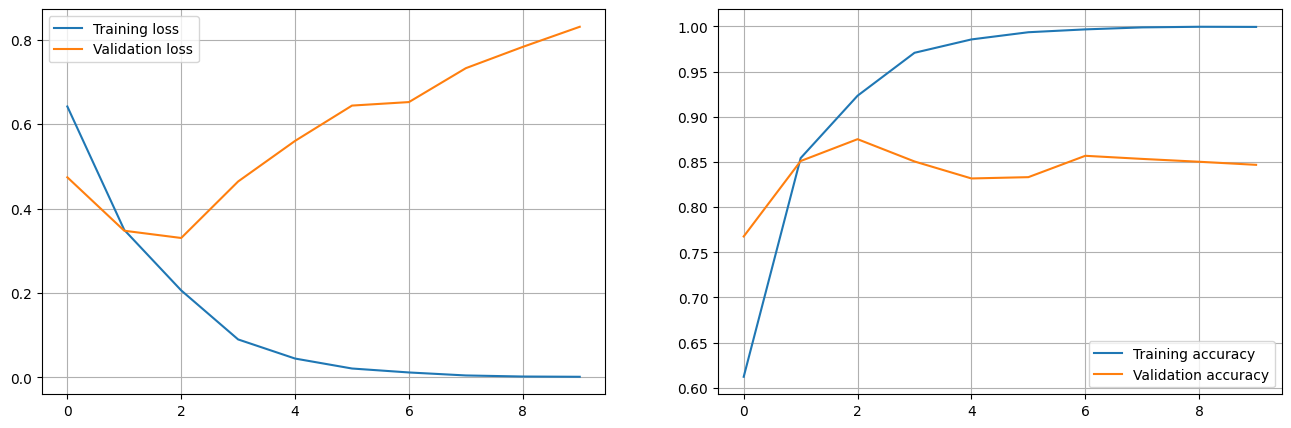

In [16]:
# plot the accuracy and loss history
metric_df = pd.DataFrame(history_vanilla.history)
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for metric, ax in zip(["loss", "accuracy"], axs):
  ax.plot(metric_df[metric], label=f'Training {metric}')
  ax.plot(metric_df['val_' + metric], label=f'Validation {metric}')
  ax.grid(True)
  ax.legend()

Run a prediction on a new sentence. If the prediction is greather than 0.5, it is positive else it is negative.

In [17]:
sample_text_pos = ["""The restaurant was excellent. The staff were friendly and attentive,
the food was fresh and delicious, and the service was very efficient.
I would happily visit this place again."""]

sample_text_neg = ["""The restaurant was disappointing. The service was slow,
the staff were inattentive, and the food arrived cold and tasted bland.
I would not recommend this place."""]

sample_sequence_pos = text_vectorizer(sample_text_pos)
sample_sequence_neg = text_vectorizer(sample_text_neg)


In [18]:
model_vanilla.predict(sample_sequence_neg)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 728ms/step


array([[1.891725e-06]], dtype=float32)

## 2.3 LSTM Model

Next, we will use a *Long Short-Term Memory* model. A bidirectional RNN with LSTM blocks is usually a reasonable first thing to try. To faciliate model comparison, we use the same hyperparameters as before. You will notice in the model summary that the LSTM model has a larger number of paramenters than the vanilla model.


In [19]:
# hyperparameters
embedding_dim = 100
state_dim = 64
dense_dim = 32

# model definition
model_lstm = Sequential([layers.Input(shape=(max_length,), dtype='int64'),
                         layers.Embedding(text_vectorizer.vocabulary_size(), embedding_dim),
                         layers.Bidirectional(layers.LSTM(state_dim)),
                         layers.Dense(dense_dim, activation='relu'),
                         layers.Dense(1, activation='sigmoid')], name="lstm")

# set the training parameters
model_lstm.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# print the model summary
model_lstm.summary()

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 120, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,088,641 (4.15 MB)

 Trainable params: 1,088,641 (4.15 MB)

 Non-trainable params: 0 (0.00 B)

The output of the bidirectional layer has a shape of `(128,)`, implying that only the hidden states of the forward and backward RNNs will be passed to the rest of the model.

In [20]:
# train the model
history_lstm = model_lstm.fit(training_ds, training_labels, batch_size=256, epochs=10, validation_data=(testing_ds, testing_labels))

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.7597 - loss: 0.4732 - val_accuracy: 0.8861 - val_loss: 0.2786
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.9081 - loss: 0.2379 - val_accuracy: 0.8900 - val_loss: 0.2656
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.9360 - loss: 0.1764 - val_accuracy: 0.8917 - val_loss: 0.2746
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.9509 - loss: 0.1384 - val_accuracy: 0.8877 - val_loss: 0.3225
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.9639 - loss: 0.1079 - val_accuracy: 0.8865 - val_loss: 0.3294
Epoch 6/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.9706 - loss: 0.0863 - val_accuracy: 0.8843 - val_loss: 0.3891
Epoch 7/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.9764 - loss: 0.0713 - val_accuracy: 0.8827 - val_loss: 0.4178
Epoch 8/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.9846 - loss: 0.0487 - val_accuracy: 0.8808 - v

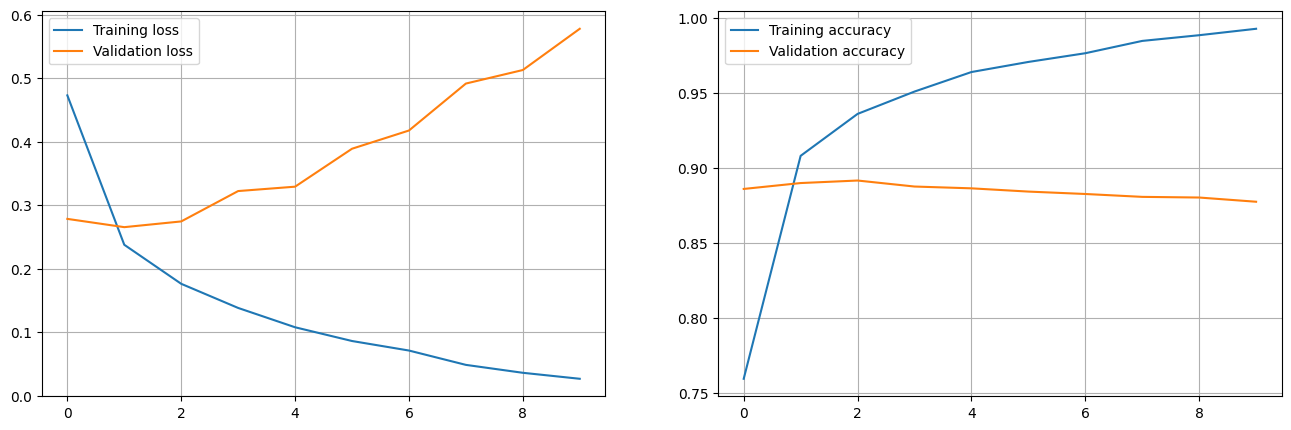

In [21]:
# plot the accuracy and loss history
metric_df = pd.DataFrame(history_lstm.history)
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for metric, ax in zip(["loss", "accuracy"], axs):
    ax.plot(metric_df[metric], label=f'Training {metric}')
    ax.plot(metric_df['val_' + metric], label=f'Validation {metric}')
    ax.grid(True)
    ax.legend()


In [22]:
model_lstm.predict(sample_sequence_neg)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step


array([[4.862099e-07]], dtype=float32)

## 2.4 GRU Model

The *Gated Recurrent Unit* is usually referred to as a simpler version of the LSTM. It can be used when you want faster results and can sacrifice some accuracy.

In [23]:
# hyperparameters
embedding_dim = 100
state_dim = 64
dense_dim = 32

# model definition
model_gru = Sequential([layers.Input(shape=(max_length,), dtype='int64'),
                        layers.Embedding(text_vectorizer.vocabulary_size(), embedding_dim),
                        layers.Bidirectional(layers.GRU(state_dim)),
                        layers.Dense(dense_dim, activation='relu'),
                        layers.Dense(1, activation='sigmoid')], name="gru")

# set the training parameters
model_gru.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# print the model summary
model_gru.summary()

Model: "gru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 120, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │        63,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,067,905 (4.07 MB)

 Trainable params: 1,067,905 (4.07 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# train the model
history_gru = model_gru.fit(training_ds, training_labels, batch_size=256, epochs=10, validation_data=(testing_ds, testing_labels))

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.7232 - loss: 0.5239 - val_accuracy: 0.8508 - val_loss: 0.3508
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.8834 - loss: 0.2896 - val_accuracy: 0.8848 - val_loss: 0.2816
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9239 - loss: 0.2029 - val_accuracy: 0.8788 - val_loss: 0.3002
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.9402 - loss: 0.1658 - val_accuracy: 0.8854 - val_loss: 0.3010
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9520 - loss: 0.1349 - val_accuracy: 0.8853 - val_loss: 0.3115
Epoch 6/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9653 - loss: 0.1042 - val_accuracy: 0.8829 - val_loss: 0.3608
Epoch 7/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.9761 - loss: 0.0742 - val_accuracy: 0.8782 - val_loss: 0.3913
Epoch 8/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.9844 - loss: 0.0523 - val_accuracy: 0.8757 - v

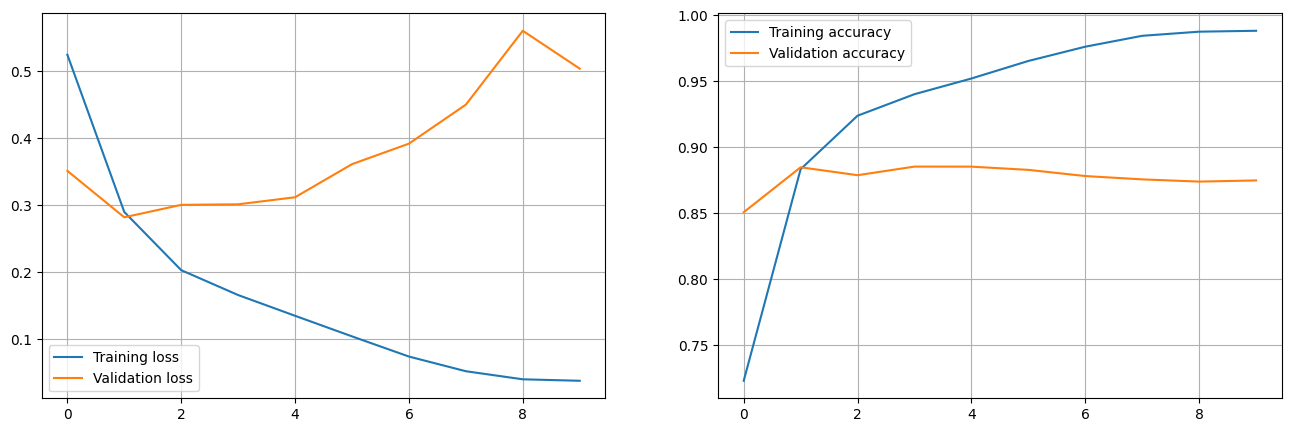

In [25]:
# plot the accuracy and loss history
metric_df = pd.DataFrame(history_gru.history)
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for metric, ax in zip(["loss", "accuracy"], axs):
    ax.plot(metric_df[metric], label=f'Training {metric}')
    ax.plot(metric_df['val_' + metric], label=f'Validation {metric}')
    ax.grid(True)
    ax.legend()


In [26]:
model_gru.predict(sample_sequence_neg)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step


array([[6.211894e-06]], dtype=float32)

## 3 Multi-layer RNNs

We can build multiple layer LSTM models by simply appending `LSTM` layers in the `Sequential` container and enabling the `return_sequences` flag to `True`.  This is because an `LSTM` layer expects a sequence input so if the previous layer is also an LSTM, then it should output a sequence as well.



In [27]:
# hyperparameters
embedding_dim = 100
state_dim = 64
dense_dim = 32


# model definition
model_multi_layer = Sequential([layers.Input(shape=(max_length,), dtype='int64'),
                                layers.Embedding(text_vectorizer.vocabulary_size(), embedding_dim),
                                layers.Bidirectional(layers.LSTM(state_dim, return_sequences=True)),
                                layers.Bidirectional(layers.LSTM(state_dim, return_sequences=True)),
                                layers.Bidirectional(layers.LSTM(state_dim)),
                                layers.Dense(dense_dim, activation='relu'),
                                layers.Dense(1, activation='sigmoid')], name="multi_layer")

# set the training parameters
model_multi_layer.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# print the model summary
model_multi_layer.summary()

Model: "multi_layer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 120, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 120, 128)       │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 120, 128)       │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,286,273 (4.91 MB)

 Trainable params: 1,286,273 (4.91 MB)

 Non-trainable params: 0 (0.00 B)

Note that the outputs of both intermediate bidirectional RNNs have a shape of `(120, 128)`. It implies that the hidden states at 120 time steps have all been passed to the rest of the model when `return_sequences` is `True`.


In [28]:
# train the model
history_multi_layer = model_multi_layer.fit(training_ds, training_labels, batch_size=256, epochs=10, validation_data=(testing_ds, testing_labels))

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 13s 86ms/step - accuracy: 0.7723 - loss: 0.4675 - val_accuracy: 0.8838 - val_loss: 0.2855
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - accuracy: 0.9056 - loss: 0.2401 - val_accuracy: 0.8854 - val_loss: 0.2761
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.9366 - loss: 0.1730 - val_accuracy: 0.8840 - val_loss: 0.2955
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.9548 - loss: 0.1284 - val_accuracy: 0.8829 - val_loss: 0.3096
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - accuracy: 0.9674 - loss: 0.0953 - val_accuracy: 0.8790 - val_loss: 0.3724
Epoch 6/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - accuracy: 0.9770 - loss: 0.0694 - val_accuracy: 0.8762 - val_loss: 0.4120
Epoch 7/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.9799 - loss: 0.0613 - val_accuracy: 0.8715 - val_loss: 0.4298
Epoch 8/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 86ms/step - accuracy: 0.9866 - loss: 0.0408 - val_accuracy: 0.8714 - 

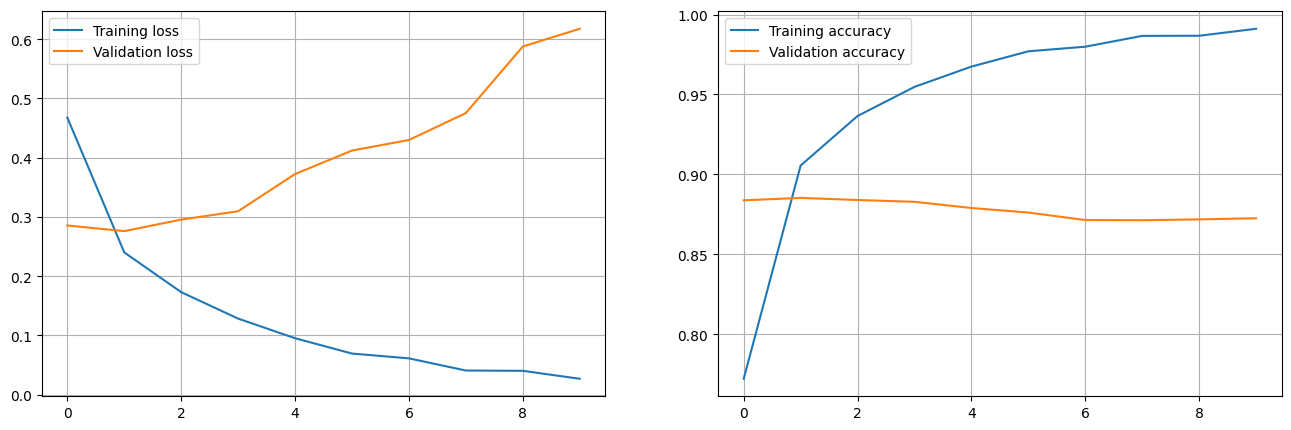

In [29]:
# plot the accuracy and loss history
metric_df = pd.DataFrame(history_multi_layer.history)
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for metric, ax in zip(["loss", "accuracy"], axs):
    ax.plot(metric_df[metric], label=f'Training {metric}')
    ax.plot(metric_df['val_' + metric], label=f'Validation {metric}')
    ax.grid(True)
    ax.legend()


In [30]:
model_multi_layer.predict(sample_sequence_neg)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step


array([[0.00023366]], dtype=float32)

## 4 RNNs with Pre-trained Word Embeddings

We will use GloVe (Global Vectors for Word Representation), a pre-trained word embedding method that represents words as dense numerical vectors based on word co-occurrence statistics from large text corpora.


The pre-trained GloVe model contains 100-dimensional vector representations for words learned from a large external text corpus. Instead of downloading and reading the GloVe text file manually, we can use **Gensim** to directly download and load the pre-trained word vectors.

**Gensim** is a Python library for natural language processing and vector-space modelling. We use Gensim's convenient Downloader API to access and load pre-trained GloVe word embeddings.

In [31]:
%pip install -q gensim

In [32]:
import gensim.downloader as api

embeddings_index = api.load("glove-wiki-gigaword-100")

[==================================================] 100.0% 128.1/128.1MB downloaded


The pre-trained GloVe model contains 100-dimensional word vectors for 400,000 distinct words. We use Gensim to directly download and load these pre-trained word vectors into **embeddings_index**, allowing us to easily retrieve the vector representation of a word.

In [33]:
print(f"Found {len(embeddings_index)} word vectors.")
print(f"Number of dimensions: {embeddings_index['hi'].shape}")

Found 400000 word vectors.
Number of dimensions: (100,)


We will now match the pre-trained GloVe word embeddings with the vocabulary created earlier by `TextVectorization`. The vocabulary is available through `text_vectorizer.get_vocabulary()`, so we can use it to construct the pre-trained embedding matrix.


In [34]:
# Reuse the vocabulary learned by TextVectorization
vocab = text_vectorizer.get_vocabulary()
vocab_size_actual = len(vocab)

# Create index-to-word and word-to-index lookups
index_word = dict(enumerate(vocab))
word_index = {word: i for i, word in index_word.items()}

for i, word in enumerate(vocab[:10]):
    print(f'{i}: {word}')


0: 
1: [UNK]
2: the
3: and
4: i
5: to
6: a
7: was
8: of
9: it


In [35]:
for word, idx in list(word_index.items())[:10]:
    print(f'{word}: {idx}')


: 0
[UNK]: 1
the: 2
and: 3
i: 4
to: 5
a: 6
was: 7
of: 8
it: 9


The following code creates the embedding matrix with its $i$-th row containing the word vector for the $i$-th word in the dictionary:

In [36]:
# Build an embedding matrix aligned with the TextVectorization vocabulary
embedding_dim = 100
embedding_matrix = np.zeros((vocab_size_actual, embedding_dim))

for i, word in enumerate(vocab):
    if i < 2:  # index 0 is padding, index 1 is [UNK]
        continue

    if word in embeddings_index:
        embedding_matrix[i] = embeddings_index[word]

print(embedding_matrix.shape)


(10000, 100)


Now, you can verify several rows in `embedding_matrix` with the corresponding entries in  `embeddings_index`:

In [37]:
# index 0 is reserved for padding; index 1 represents [UNK]
idx = 2
word = index_word[idx]

print(f"The word associated with index {idx} is '{word}'")

if word in embeddings_index:
  print(embedding_matrix[idx, :] == embeddings_index[word])

The word associated with index 2 is 'the'
[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True]


In [38]:
idx = 5
word = index_word[idx]

print(f"The word associated with index {idx} is '{word}'")

if word in embeddings_index:
  print(embedding_matrix[idx, :] == embeddings_index[word])

The word associated with index 5 is 'to'
[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True]


Now, to create a model that uses the pretrained glove embeddings instead of directly learning them from the training data, the [`Embedding` layer](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Embedding) should be defined as

```python
layers.Embedding(vocab_size_actual, embedding_dim, input_shape=(max_length,),
                 embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
                 trainable=False)
```

or

```python
layers.Embedding(vocab_size_actual, embedding_dim, input_shape=(max_length,), weights=[embedding_matrix], trainable=False),
```
`trainable=False` ensures these vectors will be unchanged over the period of training.


This means that the GloVe word vectors are used as they are and will not be updated during training. Only the RNN and Dense layers will learn from the Yelp reviews.After training the model, compare the training accuracy and validation accuracy with the previous models.

In [39]:
# hyperparameters
embedding_dim = 100
state_dim = 64
dense_dim = 32


# model definition
model_multi_glove = Sequential([layers.Embedding(vocab_size_actual, embedding_dim, input_shape=(max_length,),
                                                 embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
                                                 trainable=False),
                                layers.Bidirectional(layers.LSTM(state_dim, return_sequences=True)),
                                layers.Bidirectional(layers.LSTM(state_dim, return_sequences=True)),
                                layers.Bidirectional(layers.LSTM(state_dim)),
                                layers.Dense(dense_dim, activation='relu'),
                                layers.Dense(1, activation='sigmoid')], name="multi_layer")

# set the training parameters
model_multi_glove.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# print the model summary
model_multi_glove.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "multi_layer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 120, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_6 (Bidirectional) │ (None, 120, 128)       │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_7 (Bidirectional) │ (None, 120, 128)       │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_8 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,286,273 (4.91 MB)

 Trainable params: 286,273 (1.09 MB)

 Non-trainable params: 1,000,000 (3.81 MB)

In [40]:
# train the model
history_multi_glove = model_multi_glove.fit(training_ds, training_labels, batch_size=256, epochs=10, validation_data=(testing_ds, testing_labels))

Epoch 1/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 15s 97ms/step - accuracy: 0.7164 - loss: 0.5457 - val_accuracy: 0.8111 - val_loss: 0.4218
Epoch 2/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.8111 - loss: 0.4106 - val_accuracy: 0.8319 - val_loss: 0.3769
Epoch 3/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - accuracy: 0.8330 - loss: 0.3710 - val_accuracy: 0.8400 - val_loss: 0.3513
Epoch 4/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step - accuracy: 0.8441 - loss: 0.3502 - val_accuracy: 0.8558 - val_loss: 0.3280
Epoch 5/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.8589 - loss: 0.3227 - val_accuracy: 0.8594 - val_loss: 0.3202
Epoch 6/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step - accuracy: 0.8632 - loss: 0.3180 - val_accuracy: 0.8594 - val_loss: 0.3204
Epoch 7/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 82ms/step - accuracy: 0.8748 - loss: 0.2918 - val_accuracy: 0.8717 - val_loss: 0.2950
Epoch 8/10
98/98 ━━━━━━━━━━━━━━━━━━━━ 8s 79ms/step - accuracy: 0.8840 - loss: 0.2743 - val_accuracy: 0.8778 - 

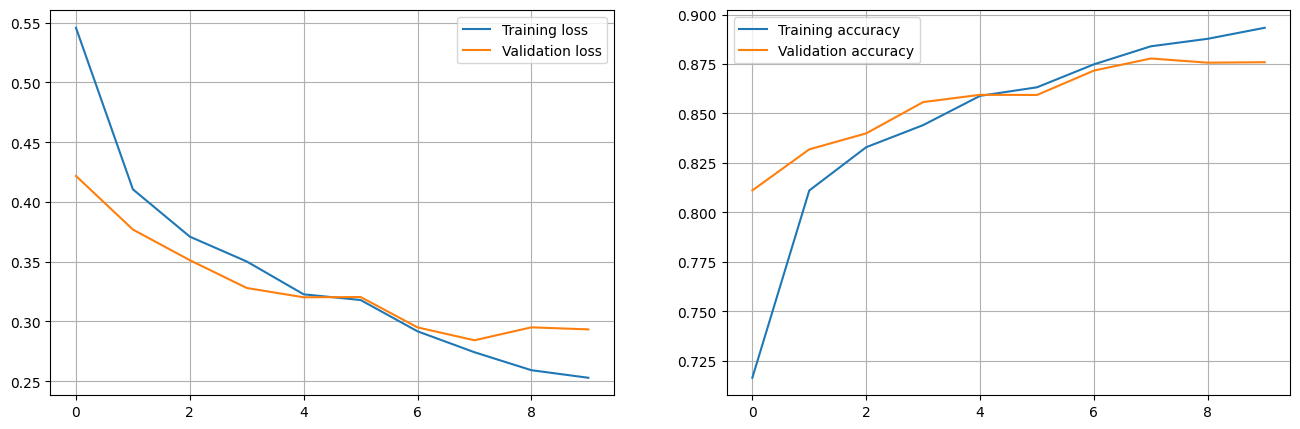

In [41]:
# plot the accuracy and loss history
metric_df = pd.DataFrame(history_multi_glove.history)
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for metric, ax in zip(["loss", "accuracy"], axs):
  ax.plot(metric_df[metric], label=f'Training {metric}')
  ax.plot(metric_df['val_' + metric], label=f'Validation {metric}')
  ax.grid(True)
  ax.legend()

**Observe**: How well does the model perform when the pre-trained word embeddings are kept fixed? Is the result better or worse than the models that learned their own embeddings from the Yelp reviews?

In the previous CNN lab, we learned that a pre-trained CNN contains many layers. During fine-tuning, we normally keep most of the pre-trained network frozen and gradually unfreeze some of the higher layers. This helps preserve useful features learned by the pre-trained model.

GloVe is different. It does not consist of a stack of neural-network layers. Instead, the pre-trained GloVe embeddings are stored in a single embedding matrix, where each row represents the vector of a word. Therefore, there are no "higher GloVe layers" that we can selectively unfreeze.

Return to the model definition and change: `trainable=True`

**Observe**: How does the training and validation performance change after the GloVe embeddings become trainable? Why might fine-tuning the general-purpose GloVe vectors help with Yelp sentiment classification?